In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Crude Oil

In [76]:
def get_oil_data(fill_method = None):
    # Read raw oil data
    oil = pd.read_csv("DCOILWTICO.csv")

    # Format oil table columns and data types
    oil.columns = ["date", "wti_price"]

    oil["date"] = pd.to_datetime(oil["date"], errors="coerce")
    oil["wti_price"] = pd.to_numeric(oil["wti_price"], errors="coerce")

    oil = (
        oil.dropna(subset=["date"])
           .drop_duplicates(subset="date")
           .sort_values("date")
           .set_index("date")
    )

    if fill_method == "ffill":
        oil = oil.ffill()
    elif not fill_method:
        oil = oil.dropna(subset=["wti_price"])
    else:
        raise ValueError("fill_method must be 'ffill' or None")

    return oil

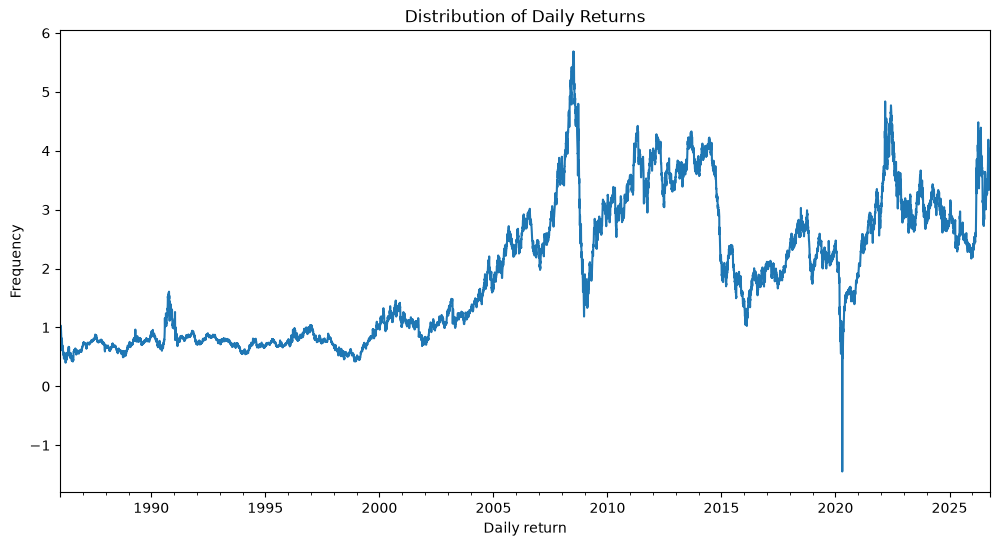

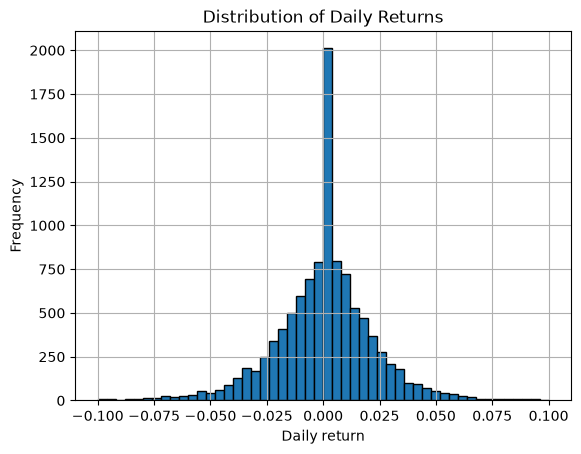

In [42]:
oil = get_oil_data(fill_method="ffill")

oil["daily return"] = oil['wti_price'].pct_change()
oil["cumulative return"] = (1 + oil["daily return"]).cumprod()

oil["cumulative return"].plot(title="WTI Oil Cumulative Return", figsize=(12, 6))
plt.xlabel("Daily return")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Returns")
plt.show()

# Plot histogram of daily returns
oil["daily return"].dropna().hist(bins = 50, range = (-0.10, 0.10), edgecolor="black")

plt.xlabel("Daily return")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Returns")
plt.show()

In [44]:
# Last available price in each week ending Friday
oil_weekly = oil[["wti_price"]].resample("W-FRI").last()

# Week-to-week return
oil_weekly["weekly return"] = (
    oil_weekly["wti_price"].pct_change(fill_method=None)
)

# Cumulative return since the first weekly price
oil_weekly["cumulative return"] = (
    (1 + oil_weekly["weekly return"]).cumprod() - 1
)

oil_weekly

,wti_price,weekly return,cumulative return
date,,,
1986-01-03,26.00,NaN,NaN
1986-01-10,25.65,-0.013462,-0.013462
1986-01-17,23.63,-0.078752,-0.091154
1986-01-24,19.45,-0.176894,-0.251923
1986-01-31,19.58,0.006684,-0.246923
...,...,...,...
2026-09-18,101.44,0.001679,2.901538
2026-09-25,85.23,-0.159799,2.278077
2026-10-02,97.89,0.148539,2.765000


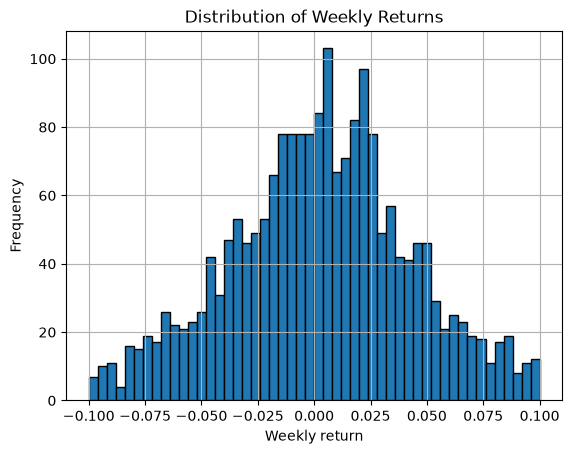

In [45]:
# Plot histogram of weekly returns
oil_weekly["weekly return"].dropna().hist(bins = 50, range = (-0.10, 0.10), edgecolor="black")

plt.xlabel("Weekly return")
plt.ylabel("Frequency")
plt.title("Distribution of Weekly Returns")
plt.show()

## Crude Oil Ending Inventory

In [52]:
# Weekly US Ending Stocks including SPR of Crude Oil
inventory = pd.read_csv(
    "Weekly_U.S._Ending_Stocks_excluding_SPR_of_Crude_Oil.csv",
    skiprows=4
)

inventory.columns = ["date", "inventory"]

inventory["date"] = pd.to_datetime(inventory["date"], 
                                   format="%m/%d/%Y",
                                   errors='coerce')

inventory["inventory"]=pd.to_numeric(inventory["inventory"], 
                                     errors='coerce')

inventory = inventory.sort_values("date").set_index("date")
inventory

inventory_weekly = inventory.asfreq("W-FRI")
inventory_weekly = inventory_weekly.ffill()

inventory_weekly["inventory_pct_change"] = inventory_weekly["inventory"].pct_change()
inventory_weekly

,inventory,inventory_pct_change
date,,
1982-08-20,338764.0,NaN
1982-08-27,336138.0,-0.007752
1982-09-03,336138.0,0.000000
1982-09-10,336138.0,0.000000
1982-09-17,336138.0,0.000000
...,...,...
2026-09-11,423429.0,-0.001509
2026-09-18,426398.0,0.007012
2026-09-25,427320.0,0.002162


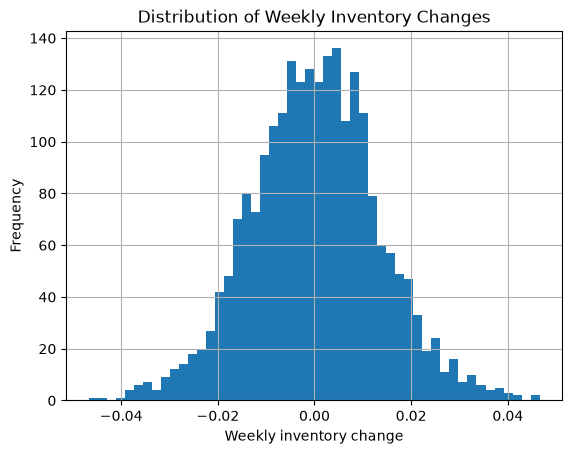

In [53]:
inventory_weekly["inventory_pct_change"].hist(bins=50)

plt.xlabel("Weekly inventory change")
plt.ylabel("Frequency")
plt.title("Distribution of Weekly Inventory Changes")
plt.show()

## US Field Production of Crude Oil

In [69]:
field_production = pd.read_csv(
    "Weekly_U.S._Ending_Stocks_excluding_SPR_of_Crude_Oil.csv",
    skiprows=4
)

field_production.columns = ["date", "field_production"]

field_production["date"] = pd.to_datetime(field_production["date"], 
                                   format="%m/%d/%Y",
                                   errors='coerce')

field_production["field_production"]=pd.to_numeric(field_production["field_production"], 
                                     errors='coerce')

field_production = field_production.sort_values("date").set_index("date")
field_production

field_production_weekly = field_production.asfreq("W-FRI")
field_production_weekly = field_production_weekly.ffill()

field_production_weekly["field_production_pct_change"] = field_production_weekly["field_production"].pct_change()
field_production_weekly

,field_production,field_production_pct_change
date,,
1982-08-20,338764.0,NaN
1982-08-27,336138.0,-0.007752
1982-09-03,336138.0,0.000000
1982-09-10,336138.0,0.000000
1982-09-17,336138.0,0.000000
...,...,...
2026-09-11,423429.0,-0.001509
2026-09-18,426398.0,0.007012
2026-09-25,427320.0,0.002162


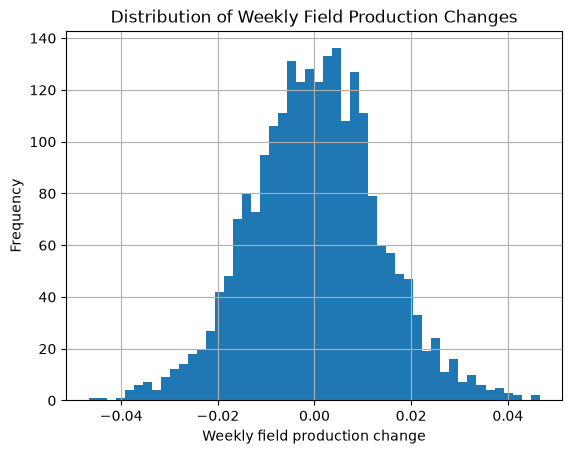

In [70]:
field_production_weekly["field_production_pct_change"].hist(bins=50)

plt.xlabel("Weekly field production change")
plt.ylabel("Frequency")
plt.title("Distribution of Weekly Field Production Changes")
plt.show()

## VIX Index

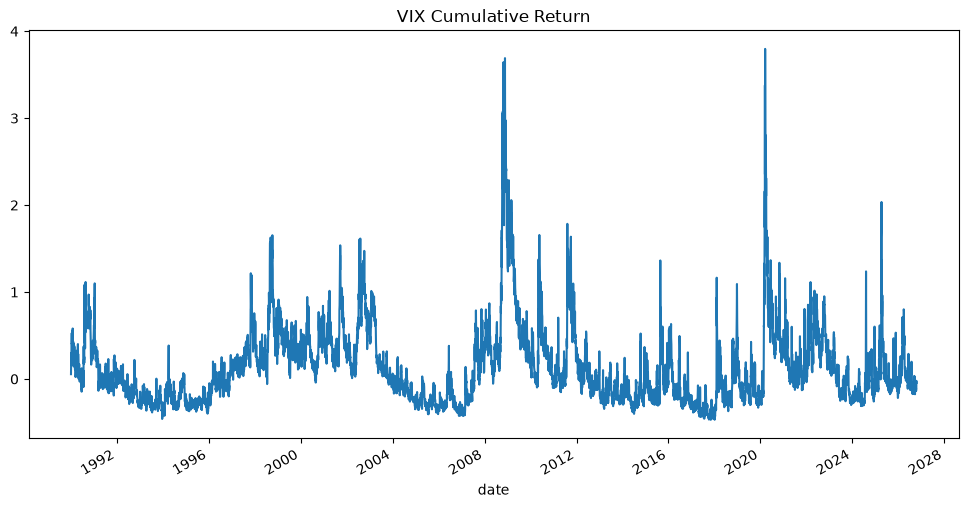

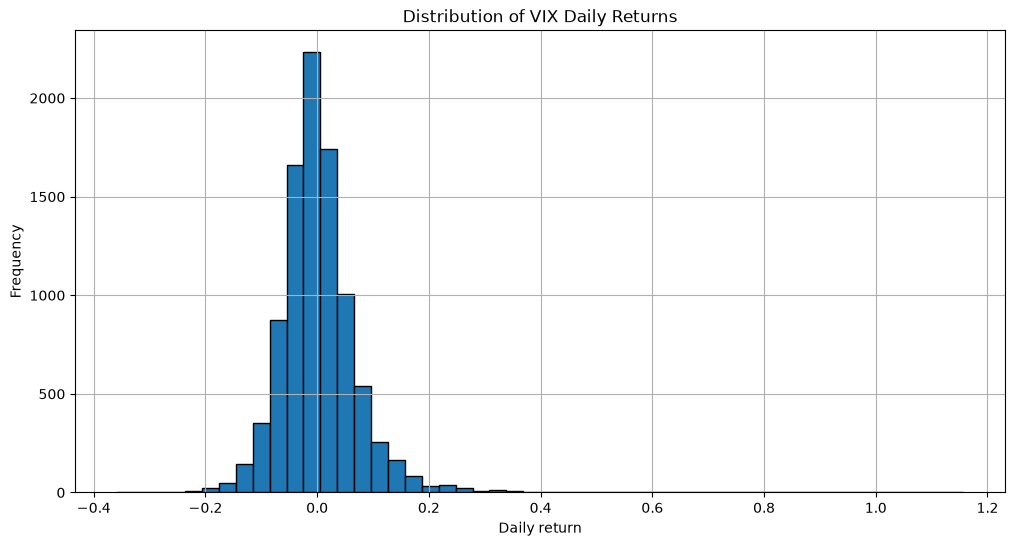

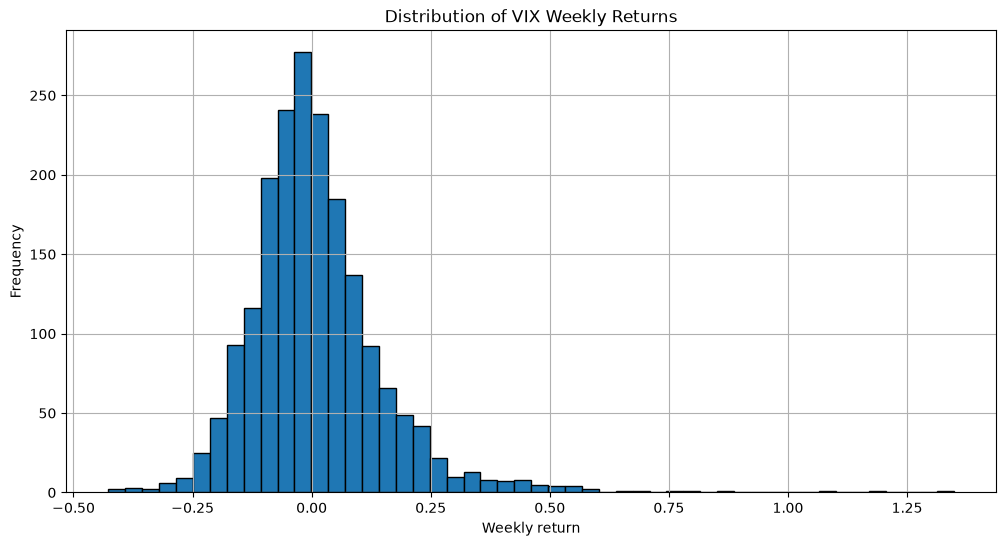

,vix_index,weekly return,cumulative return
date,,,
1990-01-05,20.11,NaN,0.000000
1990-01-12,24.64,0.225261,0.225261
1990-01-19,22.50,-0.086851,0.118846
1990-01-26,26.28,0.168000,0.306813
1990-02-02,24.32,-0.074581,0.209349
...,...,...,...
2026-09-18,14.81,-0.065025,-0.263550
2026-09-25,14.87,0.004051,-0.260567
2026-10-02,15.31,0.029590,-0.238687


In [ ]:
vix_raw = pd.read_csv("VIXCLS.csv")

vix = vix_raw.rename(columns={"observation_date": "date", "VIXCLS": "vix_index"})
vix["date"] = pd.to_datetime(vix["date"], errors="coerce")
vix["vix_index"] = pd.to_numeric(vix["vix_index"], errors="coerce")
vix = (
    vix.dropna(subset=["date", "vix_index"])
       .drop_duplicates(subset="date")
       .sort_values("date")
       .set_index("date")
)

# Daily returns and cumulative returns
vix["daily return"] = vix["vix_index"].pct_change(fill_method=None)
vix["cumulative return"] = (1 + vix["daily return"]).cumprod() - 1

vix["cumulative return"].plot(title="VIX Cumulative Return", figsize=(12, 6))
plt.show()

vix["daily return"].dropna().hist(bins=50, edgecolor="black", figsize=(12, 6))
plt.xlabel("Daily return")
plt.ylabel("Frequency")
plt.title("Distribution of VIX Daily Returns")
plt.show()

vix_weekly = vix[["vix_index"]].resample("W-FRI").last().dropna()
vix_weekly["weekly return"] = vix_weekly["vix_index"].pct_change(fill_method=None)
vix_weekly["cumulative return"] = (1 + vix_weekly["weekly return"]).cumprod() - 1
if not vix_weekly.empty:
    vix_weekly.iloc[0, vix_weekly.columns.get_loc("cumulative return")] = 0

vix_weekly["weekly return"].dropna().hist(bins=50, edgecolor="black", figsize=(12, 6))
plt.xlabel("Weekly return")
plt.ylabel("Frequency")
plt.title("Distribution of VIX Weekly Returns")
plt.show()

vix_weekly

## Data Preparation

In [71]:
field_production_weekly.head(5)

,field_production,field_production_pct_change
date,,
1982-08-20,338764.0,NaN
1982-08-27,336138.0,-0.007752
1982-09-03,336138.0,0.000000
1982-09-10,336138.0,0.000000
1982-09-17,336138.0,0.000000


In [72]:
oil_weekly_clean = oil_weekly[["weekly return"]].rename(columns={"weekly return": "oil_ret"})
inventory_weekly_clean = inventory_weekly[["inventory_pct_change"]].rename(columns={"inventory_pct_change": "inv_chg"})
field_production_weekly_clean = field_production_weekly[["field_production_pct_change"]].rename(columns={"field_production_pct_change": "fp_chg"})  
vix_weekly_clean = vix_weekly[["weekly return"]].rename(columns={"weekly return": "vix_ret"})

In [73]:
combined = pd.concat(
    [oil_weekly_clean, inventory_weekly_clean, field_production_weekly_clean, vix_weekly_clean],
    axis=1,
    join="inner"
).sort_index()
combined = combined.dropna(how="any")
combined

,oil_ret,inv_chg,fp_chg,vix_ret
date,,,,
1990-01-12,0.004335,0.011094,0.011094,0.225261
1990-01-19,0.022874,-0.005021,-0.005021,-0.086851
1990-01-26,-0.048101,-0.006285,-0.006285,0.168000
1990-02-02,0.021277,0.030868,0.030868,-0.074581
1990-02-09,-0.052951,-0.014402,-0.014402,-0.025905
...,...,...,...,...
2026-09-11,0.092567,-0.001509,-0.001509,0.090158
2026-09-18,0.001679,0.007012,0.007012,-0.065025
2026-09-25,-0.159799,0.002162,0.002162,0.004051


In [74]:
# Output to csv
combined.to_csv("../Analysis/combined_weekly_data.csv", index=True)